In [1]:
!pip install ucimlrepo -q

import pandas as pd, numpy as np
import matplotlib.pyplot as plt, seaborn as sns
from ucimlrepo import fetch_ucirepo
from sklearn.model_selection import (train_test_split, StratifiedKFold,
                                     cross_val_score)
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import make_pipeline
from sklearn.naive_bayes import BernoulliNB
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, classification_report,
                             confusion_matrix)

# Load the UCI Mushroom dataset (ID 73)
mush = fetch_ucirepo(id=73)
X = mush.data.features
y = mush.data.targets.iloc[:, 0]   # 'e' = edible, 'p' = poisonous
print(X.shape)
print(y.value_counts())

(8124, 22)
poisonous
e    4208
p    3916
Name: count, dtype: int64


In [2]:
print("Missing values:")
print(X.isna().sum()[X.isna().sum() > 0])

print("\nDuplicates:", pd.concat([X, y], axis=1).duplicated().sum())

print("\nUnique values per feature:")
print(X.nunique())

Missing values:
stalk-root    2480
dtype: int64

Duplicates: 0

Unique values per feature:
cap-shape                    6
cap-surface                  4
cap-color                   10
bruises                      2
odor                         9
gill-attachment              2
gill-spacing                 2
gill-size                    2
gill-color                  12
stalk-shape                  2
stalk-root                   4
stalk-surface-above-ring     4
stalk-surface-below-ring     4
stalk-color-above-ring       9
stalk-color-below-ring       9
veil-type                    1
veil-color                   4
ring-number                  3
ring-type                    5
spore-print-color            9
population                   6
habitat                      7
dtype: int64


In [3]:
# Keep missing stalk-root values as their own category
X = X.fillna("missing")

# Drop veil-type (same value in every record)
if "veil-type" in X.columns and X["veil-type"].nunique() == 1:
    X = X.drop(columns=["veil-type"])

# Split first (80:20, stratified), then fit the encoder on training data only
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)

enc = OneHotEncoder(handle_unknown="ignore", sparse_output=False)
Xtr = enc.fit_transform(X_train)
Xte = enc.transform(X_test)

print("Features after dropping veil-type:", X.shape[1])
print("Train:", Xtr.shape, " Test:", Xte.shape)

Features after dropping veil-type: 21
Train: (6499, 116)  Test: (1625, 116)


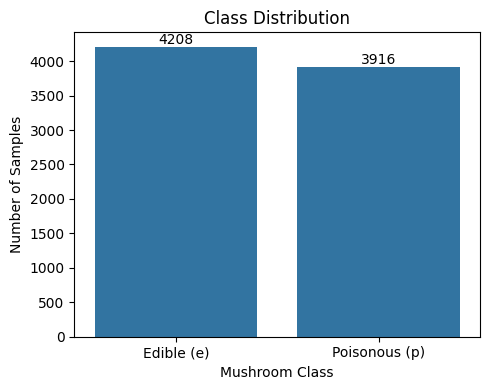

In [4]:
plt.figure(figsize=(5, 4))
ax = sns.countplot(x=y, order=["e", "p"])
ax.set_xticks([0, 1])
ax.set_xticklabels(["Edible (e)", "Poisonous (p)"])
ax.set_xlabel("Mushroom Class")
ax.set_ylabel("Number of Samples")
ax.set_title("Class Distribution")
for cont in ax.containers:
    ax.bar_label(cont)
plt.tight_layout()
plt.savefig("fig1_class_distribution.png", dpi=200, bbox_inches="tight")
plt.show()

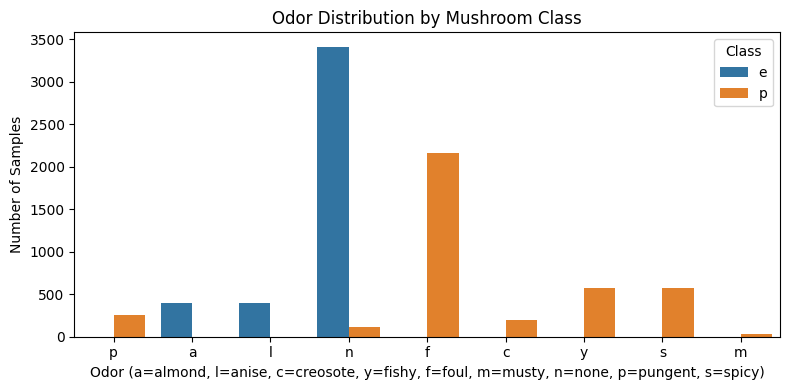

poisonous     e     p
odor                 
a           400     0
c             0   192
f             0  2160
l           400     0
m             0    36
n          3408   120
p             0   256
s             0   576
y             0   576


In [5]:
plt.figure(figsize=(8, 4))
ax = sns.countplot(x=X["odor"], hue=y, hue_order=["e", "p"])
ax.set_xlabel("Odor (a=almond, l=anise, c=creosote, y=fishy, f=foul, "
              "m=musty, n=none, p=pungent, s=spicy)")
ax.set_ylabel("Number of Samples")
ax.set_title("Odor Distribution by Mushroom Class")
ax.legend(title="Class")
plt.tight_layout()
plt.savefig("fig2_odor_by_class.png", dpi=200, bbox_inches="tight")
plt.show()

# Exact counts for the paper
print(pd.crosstab(X["odor"], y))

In [6]:
models = {
    "Naive Bayes": BernoulliNB(),
    "Decision Tree": DecisionTreeClassifier(criterion="gini", random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=100, random_state=42),
}

for name, m in models.items():
    m.fit(Xtr, y_train)
    pred = m.predict(Xte)
    print(f"\n=== {name} ===")
    print("Train acc:", accuracy_score(y_train, m.predict(Xtr)))
    print("Test acc :", accuracy_score(y_test, pred))
    print(classification_report(y_test, pred))
    print("Confusion matrix (rows = actual e,p; columns = predicted e,p):")
    print(confusion_matrix(y_test, pred, labels=["e", "p"]))


=== Naive Bayes ===
Train acc: 0.9421449453762117
Test acc : 0.932923076923077
              precision    recall  f1-score   support

           e       0.90      0.98      0.94       842
           p       0.98      0.88      0.93       783

    accuracy                           0.93      1625
   macro avg       0.94      0.93      0.93      1625
weighted avg       0.94      0.93      0.93      1625

Confusion matrix (rows = actual e,p; columns = predicted e,p):
[[829  13]
 [ 96 687]]

=== Decision Tree ===
Train acc: 1.0
Test acc : 1.0
              precision    recall  f1-score   support

           e       1.00      1.00      1.00       842
           p       1.00      1.00      1.00       783

    accuracy                           1.00      1625
   macro avg       1.00      1.00      1.00      1625
weighted avg       1.00      1.00      1.00      1625

Confusion matrix (rows = actual e,p; columns = predicted e,p):
[[842   0]
 [  0 783]]

=== Random Forest ===
Train acc: 1.0
Tes

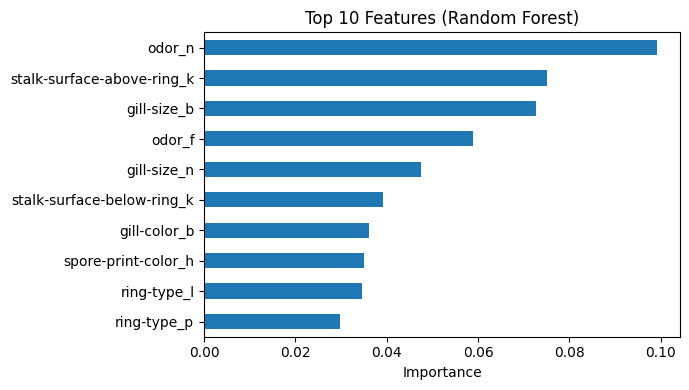

odor_n                        0.099279
stalk-surface-above-ring_k    0.075024
gill-size_b                   0.072670
odor_f                        0.058858
gill-size_n                   0.047617
stalk-surface-below-ring_k    0.039213
gill-color_b                  0.036024
spore-print-color_h           0.035014
ring-type_l                   0.034629
ring-type_p                   0.029671
dtype: float64
DT depth: 7  Leaves: 14


In [7]:
rf = models["Random Forest"]
imp = pd.Series(rf.feature_importances_,
                index=enc.get_feature_names_out()).nlargest(10)

plt.figure(figsize=(7, 4))
imp.sort_values().plot(kind="barh")
plt.xlabel("Importance")
plt.title("Top 10 Features (Random Forest)")
plt.tight_layout()
plt.savefig("fig3_feature_importance.png", dpi=200, bbox_inches="tight")
plt.show()
print(imp)

dt = models["Decision Tree"]
print("DT depth:", dt.get_depth(), " Leaves:", dt.get_n_leaves())

In [8]:
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

for name, clf in [
        ("Naive Bayes", BernoulliNB()),
        ("Decision Tree", DecisionTreeClassifier(random_state=42)),
        ("Random Forest", RandomForestClassifier(n_estimators=100,
                                                 random_state=42))]:
    pipe = make_pipeline(OneHotEncoder(handle_unknown="ignore"), clf)
    s = cross_val_score(pipe, X, y, cv=skf)
    print(f"{name}: mean={s.mean():.4f}, std={s.std():.4f}, "
          f"folds={s.round(4)}")

Naive Bayes: mean=0.9409, std=0.0071, folds=[0.9311 0.9452 0.9465 0.9335 0.9483]
Decision Tree: mean=1.0000, std=0.0000, folds=[1. 1. 1. 1. 1.]
Random Forest: mean=1.0000, std=0.0000, folds=[1. 1. 1. 1. 1.]


In [9]:
import sys, sklearn, matplotlib, seaborn
print("Python      :", sys.version.split()[0])
print("pandas      :", pd.__version__)
print("numpy       :", np.__version__)
print("matplotlib  :", matplotlib.__version__)
print("seaborn     :", seaborn.__version__)
print("scikit-learn:", sklearn.__version__)

from google.colab import files
for f in ["fig1_class_distribution.png",
          "fig2_odor_by_class.png",
          "fig3_feature_importance.png"]:
    files.download(f)

Python      : 3.13.18
pandas      : 2.2.3
numpy       : 2.4.6
matplotlib  : 3.10.0
seaborn     : 0.13.2
scikit-learn: 1.6.1


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>